# 3. From predictions to decisions: how many rooms to overbook (weeks 8-9)
A model is only useful if it leads to a better decision, measured in **euros** and **walked guests**.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hotel_ob import config, data, model, nights, policy
from hotel_ob.features import make_X
pd.options.display.float_format = "{:,.3f}".format
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## The newsvendor rule
Sell C + x rooms. Each booking is lost late with probability p. An empty room costs one room rate; a walked guest costs w room rates. The expected gain for each x:

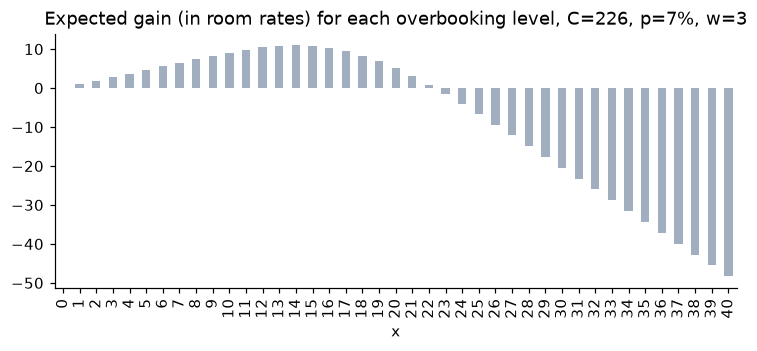

best x = 14 | chance of walking anyone at that x: 20%


In [2]:
curve = policy.expected_curve(C=226, p=0.07, w=3)
ax = curve.plot.bar(x='x', y='net_gain', figsize=(8, 3), legend=False, color='#a0aec0',
                    title='Expected gain (in room rates) for each overbooking level, C=226, p=7%, w=3')
plt.show()
x = policy.best_overbook(226, 0.07, 3)
print('best x =', x, '| chance of walking anyone at that x:', f"{curve.p_any_walk[x]:.0%}")

**Try it:** change `w` to 1 and to 5. What happens to the best x, and why?

## Room-nights and capacity
The data does not say how many rooms each hotel has. We use the busiest night ever (most guests in house).

In [3]:
n = pd.read_parquet(config.PROCESSED_DIR / 'room_nights.parquet')
cap = n.groupby('hotel').C.first()
print(cap)
n.head()

hotel
City Hotel      226
Resort Hotel    187
Name: C, dtype: int64


,hotel,night,booked,lost,p_pred,shows,adr,p_actual,C
0,City Hotel,2015-07-01,66,1,0.043,65,95.077,0.015,226
1,City Hotel,2015-07-02,72,6,0.049,66,94.525,0.083,226
2,City Hotel,2015-07-03,22,9,0.130,13,76.303,0.409,226
3,City Hotel,2015-07-04,32,10,0.117,22,71.179,0.312,226
4,City Hotel,2015-07-05,19,7,0.107,12,68.522,0.368,226


## Six rules, one test period
Every rule decides 7 days before the night, using only information available then.

In [4]:
summary, detail = policy.backtest(n, cap, w=config.WALK_MULTIPLE)
summary[['hotel', 'policy', 'avg_overbook', 'gain_eur', 'gain_pct_revenue', 'nights_with_walk', 'guests_walked']]

,hotel,policy,avg_overbook,gain_eur,gain_pct_revenue,nights_with_walk,guests_walked
0,City Hotel,No overbooking,0.000,0.000,0.000,0,0
1,City Hotel,Fixed rule (2015-16),17.000,"-39,829.449",-0.671,155,973
2,City Hotel,"Model, no update",23.864,"-336,252.803",-5.665,207,2031
3,City Hotel,Rolling 28-night rate,14.477,"134,799.731",2.271,109,510
4,City Hotel,Model + rolling update,14.897,"125,405.714",2.113,99,577
5,City Hotel,Rolling rate + clumping,8.457,"182,605.938",3.077,24,53
6,Resort Hotel,No overbooking,0.000,0.000,0.000,0,0
7,Resort Hotel,Fixed rule (2015-16),4.000,"69,743.334",1.572,34,57
8,Resort Hotel,"Model, no update",6.905,"48,385.882",1.091,97,309
9,Resort Hotel,Rolling 28-night rate,6.041,"41,164.752",0.928,88,255


At the City Hotel the model that was never updated **loses** money. Look back at notebook 01: late losses halved, but the model still expects the 2015-16 level. The rolling rule, which only looks at the last four weeks, keeps up.

## Cancellations come in clumps
The newsvendor rule above assumes each booking cancels on its own, like a coin flip. Check that on 2015-16 nights: if it were true, the standardised error below would have variance 1.

In [5]:
t = policy.add_policy_inputs(n)
t = t[t.night < config.TEST_START].dropna(subset=['p_roll'])
z = (t.lost - t.booked * t.p_roll) / np.sqrt(t.booked * t.p_roll * (1 - t.p_roll))
print(t.groupby('hotel').apply(lambda g: z[g.index].var(), include_groups=False).rename('variance (1 = coin flips)'))

hotel
City Hotel     6.257
Resort Hotel   4.723
Name: variance (1 = coin flips), dtype: float64


Nights vary several times more than coin flips allow: groups cancel together, and bad weeks come in runs. The rule `Rolling rate + clumping` uses a beta-binomial distribution with the extra spread learned from 2015-16 (`policy.estimate_clumping`).

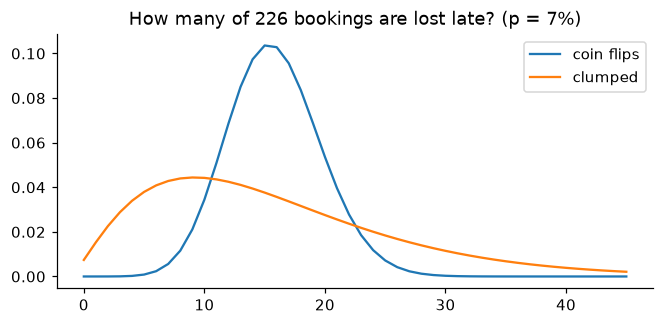

In [6]:
pmf = pd.DataFrame({'coin flips': policy.loss_pmf(226, .07), 'clumped': policy.loss_pmf(226, .07, .029)})
pmf.loc[:45].plot(figsize=(7, 3), title='How many of 226 bookings are lost late? (p = 7%)'); plt.show()

## Be honest about when you had the idea
The clumping rule was added *after* looking at the 2017 results. Judging it on the same months would be tuning on the test set. So test it on a period it never saw: learn from Jul 2015 - Jun 2016, test on Jul - Dec 2016.

In [7]:
val, _ = policy.backtest(n, cap, w=3, test_start=config.VALID_START, test_end=config.TEST_START)
val[val.policy.isin(['Rolling 28-night rate', 'Rolling rate + clumping', 'Fixed rule (2015-16)'])][
    ['hotel', 'policy', 'gain_eur', 'nights_with_walk', 'guests_walked']]

,hotel,policy,gain_eur,nights_with_walk,guests_walked
1,City Hotel,Fixed rule (2015-16),"177,484.451",73,375
3,City Hotel,Rolling 28-night rate,"179,937.746",60,358
5,City Hotel,Rolling rate + clumping,"161,575.910",10,44
7,Resort Hotel,Fixed rule (2015-16),"33,556.663",55,108
9,Resort Hotel,Rolling 28-night rate,"32,114.551",49,91
11,Resort Hotel,Rolling rate + clumping,"17,749.878",1,1


In the validation period the clumping rule earns a bit less than the plain rolling rule, but walks guests on far fewer nights. It is the **safer** rule, not a magic money machine. (The model-based rules are left out here: the model was trained on these very nights.)

### Your turn
1. Rerun the backtest with `w=1.5` and `w=5`. Which rule is best at each cost?
2. Use `max_walk_prob=0.05` in `policy.backtest`. How much revenue does a 5% service-level limit cost the plain rolling rule?
3. Change `config.ROLLING_NIGHTS` from 28 to 14 or 56 (pass `window=` to `policy.rolling_rate`). Is four weeks a good choice? Careful: which period are you allowed to pick it on?